# **US Medical Insurance Costs Analysis**

## **1. Exploratory Data Analysis Introduction**
In this notebook, the relationship between features and the target ('insurance_charges') will be explored with tables and graphs.

The exploratory data analysis aims to answer the following questions:
- Which variables are most strongly associated with charges?
- Do any variables *interact* (i.e. does the effect of one depend on another)?
- What does this imply for feature engineering in the prediction models that will be built later?

**Input:** `../data/cleaned/insurance_cleaned.csv` (output of notebook 01)

## **2. Load Prepared Data and Setup**
The prepared dataset is loaded into a pandas DataFrame for analysis. The following steps import the required libraries and provide an initial overview of the data.

In [76]:
# Import pandas for loading and analyzing tabular data.
import pandas as pd

# Import Matplotlib and Seaborn for creating visualizations.
import matplotlib.pyplot as plt
import seaborn as sns

# Import Path to build a platform-independent file path.
from pathlib import Path

# Define the path to the prepared dataset.
data_path = Path("../data/cleaned/insurance_cleaned.csv")

# Load the CSV file into a pandas DataFrame.
df = pd.read_csv(data_path)

Helper function

In [88]:
def charge_stats(col):
    """Return count, mean, median, std, min and max of charges for each level of `col`."""
    # Group the records by the chosen column and summarize the target within each group.
    return df.groupby(col)["insurance_charges"].agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )

Check the size of the data, the column types and a sample of rows.

**Data dictionary**

| Column | Type | Description |
|---|---|---|
| `age` | int | Age of the primary beneficiary (years) |
| `sex` | category | `female` / `male` |
| `bmi` | float | Body mass index (kg/m²) |
| `no_of_children` | int | Number of dependents covered by the plan |
| `smoker` | category | `yes` / `no` |
| `region` | category | US residential region (northeast, northwest, southeast, southwest) |
| `insurance_charges` | float | Individual medical costs billed by insurance (**target**) |

In [78]:
# Show the number of rows and columns in a readable format.
print("Dataset dimensions")
print(f"  Rows:    {df.shape[0]:,}")
print(f"  Columns: {df.shape[1]:,}")

# List each column and its data type.
print("\nColumn data types")
print(df.dtypes.to_string())

# Display the first 25 rows as a formatted notebook table.
print("\nFirst 25 rows")
display(df.head(25))

Dataset dimensions
  Rows:    1,337
  Columns: 7

Column data types
age                    int64
sex                      str
bmi                  float64
no_of_children         int64
smoker                   str
region                   str
insurance_charges    float64

First 25 rows


,age,sex,bmi,no_of_children,smoker,region,insurance_charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


## **3. Exploration and Relationship Analysis**

### **3.1 Age vs. Insurance Charges, by Sex**

This scatter plot shows how insurance charges change with age, with points coloured by sex. It checks whether sex shifts charges once age is taken into account.

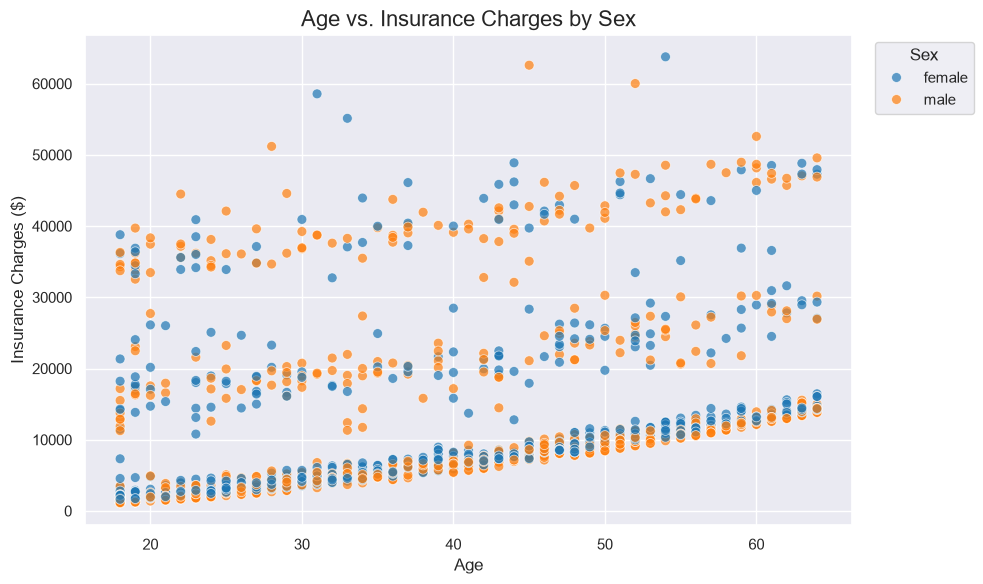

In [79]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot age against insurance charges, with a different color for each sex.
sns.scatterplot(
    data=df,
    x="age",
    y="insurance_charges",
    hue="sex",
    palette="tab10",
    s=50,        # Set the marker size.
    alpha=0.7    # Make markers slightly transparent to reveal overlap.
)

# Add a title and labels for both axes.
plt.title("Age vs. Insurance Charges by Sex", fontsize=16)
plt.xlabel("Age")
plt.ylabel("Insurance Charges ($)")

# Place the legend outside the plot on the right.
plt.legend(title="Sex", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Display the chart.
plt.show()

**Observations**
- Charges rise steadily with age, and the points form **three distinct bands** rather than a single cloud.
- The lowest band (roughly $1k–$16k) holds most records and has a tight, upward slope with age.
- Female and male points are **interleaved in every band**. Neither sex sits consistently higher or lower, so sex does not appear to explain the banding or shift charges at a given age.

**Interpretation**
At every age, charges fall into one of three bands, and sex does not determine which band a person is in. Something else must separate the bands. The age vs. smoker plot in the next section tests whether smoking does.

**Implication for modelling:** `age` has a clear, steady positive effect and should be a core feature. `sex` shows no visible effect in this view, so it is likely a weak predictor.

### **3.2 Age vs. Insurance Charges, by Smoker Status**

The same age vs. charges scatter plot as before, now coloured by smoker status. The previous plot showed three distinct bands of charges that sex did not explain. This plot tests whether smoking does.

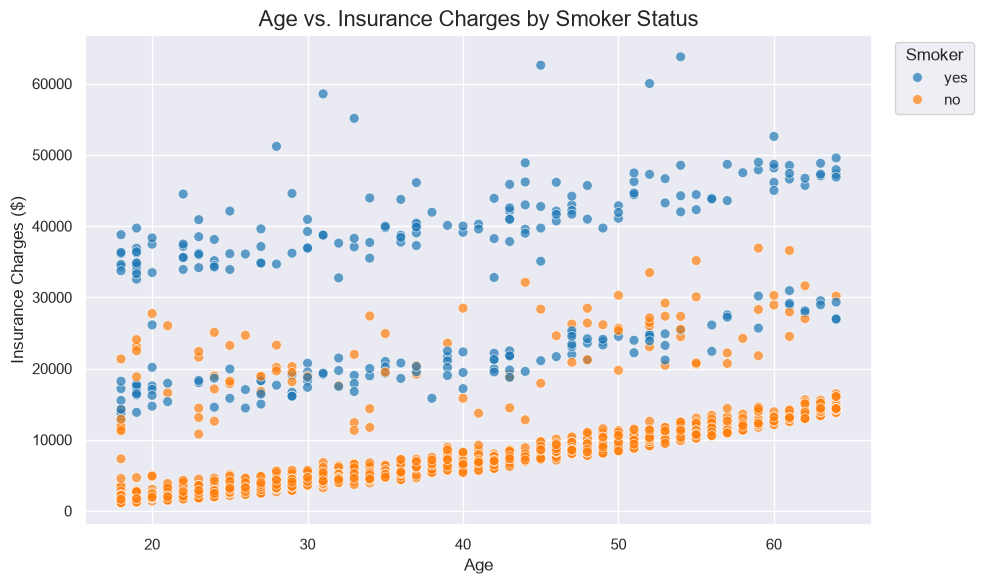

In [80]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot age against insurance charges, with a different color for smokers and non-smokers.
sns.scatterplot(
    data=df,
    x="age",
    y="insurance_charges",
    hue="smoker",
    palette="tab10",
    s=50,        # Set the marker size.
    alpha=0.7    # Make markers slightly transparent to reveal overlap.
)

# Add a title and labels for both axes.
plt.title("Age vs. Insurance Charges by Smoker Status", fontsize=16)
plt.xlabel("Age")
plt.ylabel("Insurance Charges ($)")

# Place the legend outside the plot on the right.
plt.legend(title="Smoker", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Display the chart.
plt.show()

**Observations**
- **Bottom band (roughly $1k–$16k):** almost entirely non-smokers (orange). It rises in a tight, steady line with age, so for non-smokers, age is a strong and predictable driver of charges.
- **Top band (roughly $33k–$50k+):** almost entirely smokers (blue). It also rises with age, but more gradually. A handful of non-smokers reach $33k–$37k, but **every charge above about $37k is a smoker**.
- **Middle band (roughly $12k–$37k):** a **mix of smokers and non-smokers**. The smokers in this band appear to have lower BMI (see the next plot). The non-smokers here are not explained by smoking.

**Interpretation**
Smoking explains the separation between the bottom and top bands, so it is the dominant driver of charges. It does not fully explain the middle band, which means at least one other factor is raising charges for some people.

**Implication for modelling:**
- `smoker` is a core feature. Its effect is much larger than that of any other variable.
- Smoking changes the *level* of charges and also how fast they grow with age, so an `age × smoker` interaction should be tested for linear models.

### **3.3 BMI vs. Insurance Charges, by Smoker Status**

This scatter plot shows how insurance charges vary with BMI, with points coloured by smoker status. It checks whether the relationship between BMI and charges differs for smokers and non-smokers.

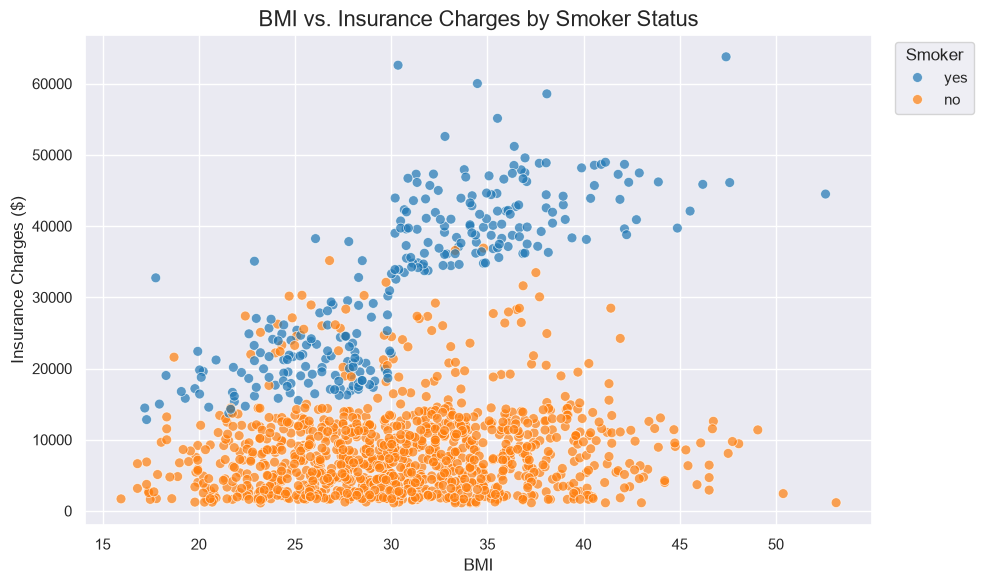

In [81]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot BMI against insurance charges, with a different color for smokers and non-smokers.
sns.scatterplot(
    data=df,
    x="bmi",
    y="insurance_charges",
    hue="smoker",
    palette="tab10",
    s=50,        # Set the marker size.
    alpha=0.7    # Make markers slightly transparent to reveal overlap.
)

# Add a title and labels for both axes.
plt.title("BMI vs. Insurance Charges by Smoker Status", fontsize=16)
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")

# Place the legend outside the plot on the right.
plt.legend(title="Smoker", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Display the chart.
plt.show()

**Observations**
- **Smokers (blue) are clearly separated from non-smokers (orange).** Almost every smoker has higher charges than the bulk of non-smokers at the same BMI.
- **Non-smokers:** charges are mostly below about $15k, and the cloud is roughly flat across the whole BMI range. A higher BMI does not push their charges up in any obvious way.
- **Smokers:** charges rise with BMI, and there is a visible **step around BMI 30**. Smokers below 30 mostly fall between roughly $14k and $38k, while most smokers above 30 sit at about $33k–$50k, with a few outliers above $55k.
- A smaller group of non-smokers reaches $15k–$30k at BMI values of about 25–42. This may be the non-smoker group in the middle band seen in the age plot, and is worth investigating.

**Interpretation**
BMI appears to matter mainly for smokers, and mainly above the obesity threshold of 30. For non-smokers it has little visible effect. This is an **interaction effect** (`smoker × BMI`): the effect of BMI depends on smoking status.

**Implication for modelling:** a `smoker × bmi` interaction term, and an `obese` flag (BMI ≥ 30) combined with smoker status, will be tested for linear models.

### **3.4 BMI vs. Insurance charges, by Sex**

The same BMI vs. charges scatter plot as before, now coloured by sex. It checks whether sex changes the relationship between BMI and charges.

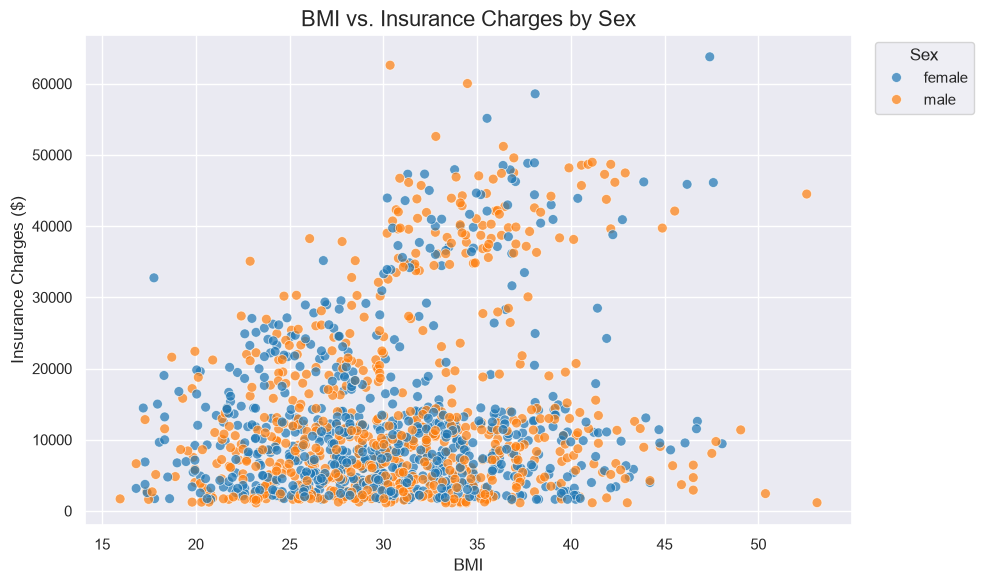

In [82]:
# Apply a dark grid style to the plot.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Plot BMI against insurance charges, with a different color for each sex.
sns.scatterplot(
    data=df,
    x="bmi",
    y="insurance_charges",
    hue="sex",
    palette="tab10",
    s=50,        # Set the marker size.
    alpha=0.7    # Make markers slightly transparent to reveal overlap.
)

# Add a title and labels for both axes.
plt.title("BMI vs. Insurance Charges by Sex", fontsize=16)
plt.xlabel("BMI")
plt.ylabel("Insurance Charges ($)")

# Place the legend outside the plot on the right.
plt.legend(title="Sex", bbox_to_anchor=(1.02, 1), loc="upper left")

# Adjust spacing so the plot and legend fit neatly.
plt.tight_layout()

# Display the chart.
plt.show()

**Observations**

- Female and male points are **mixed together across the whole BMI range**, in both the low-cost cluster (mostly below about $15k) and the high-cost cluster (above about $33k at BMI 30+).
- The step up in charges around **BMI 30** appears for both sexes, so it is not specific to men or women.
- No separate trend is visible for either sex, and the highest charges are not concentrated in one group.

**Interpretation**
Sex does not appear to change how BMI relates to charges. The high-cost cluster seen here is the smoker group from the previous plot, and it contains both sexes.

**Implication for modelling:** `sex` looks like a weak predictor in both the age and BMI views. It will be kept in the baseline model and dropped only if testing shows it adds nothing.

### Takeaways in all the scatter plots
- **Smoker status** is the strongest driver of charges and explains the main separation in either plots.
- **Age** raises charges steadily within every group.
- **BMI** matters mainly for smokers above BMI 30 (a `smoker × BMI` interaction).
- **Sex** shows no visible effect in either plot.
- A group of non-smokers with mid-range charges is still unexplained and needs further investigation.

### **3.5 Insurance Charges by region**

Boxplots compare the distribution of charges across the four US regions. The box shows the middle 50% of charges, the line inside it is the median, and the dots are outliers. This checks whether where someone lives is associated with how much they are charged.

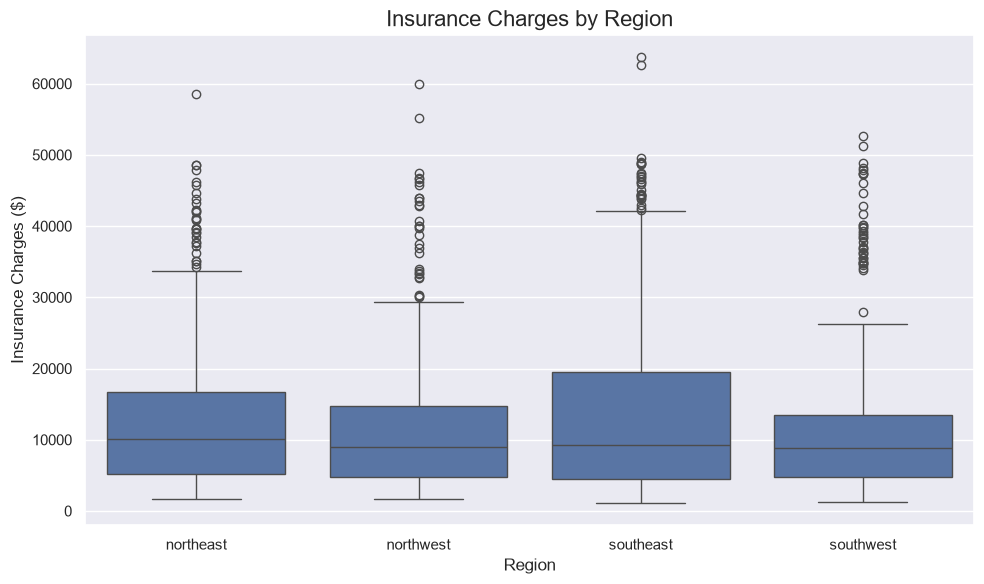

In [83]:
# Apply a dark grid style.
sns.set_theme(style="darkgrid")

# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Draw one box per region, in a fixed alphabetical order.
sns.boxplot(
    data=df,
    x="region",
    y="insurance_charges",
    order=["northeast", "northwest", "southeast", "southwest"]
)

# Add a title and labels for both axes.
plt.title("Insurance Charges by Region", fontsize=16)
plt.xlabel("Region")
plt.ylabel("Insurance Charges ($)")

# Adjust spacing so the plot fits neatly, then display the chart.
plt.tight_layout()
plt.show()

**Observations**
- The four regions look **very similar**. Medians are close together, at about $8.8k to $10.1k, and the boxes overlap heavily.
- The **southeast** stands out slightly: it has the tallest box (the widest spread of typical charges), the highest mean (about $14.7k) and the single most expensive record (about $64k).
- **Every region has a long column of high outliers**, starting at about $30k to $42k depending on the region. These are the high-cost records seen earlier, which are largely smokers.
- Regions are about the same size (324 to 364 records each), so the comparison is not distorted by group size.

**Interpretation**
Region has at most a weak association with charges. The differences between regions are small compared with the spread of charges inside each region. The southeast's higher mean is probably driven by its tail of expensive records rather than by a shift for everyone in the region. 

**Implication for modelling:** `region` could be used in model implementation.

### Charge statistics by region
Exact numbers behind the region boxplot. Medians are shown next to means because the charges are right-skewed, so a few very expensive records pull the mean up.

In [84]:
# Summarize charges by region, sorted from highest to lowest mean.
region_charge_stats = charge_stats("region").sort_values("mean", ascending=False)

# Display the table with values rounded to two decimals.
display(region_charge_stats.round(2))

,count,mean,median,std,min,max
region,,,,,,
southeast,364,14735.41,9294.13,13971.10,1121.87,63770.43
northeast,324,13406.38,10057.65,11255.80,1694.80,58571.07
northwest,324,12450.84,8976.98,11073.13,1621.34,60021.40
southwest,325,12346.94,8798.59,11557.18,1241.56,52590.83


**Observations**
- The four regions are similar in size (324 to 364 records), so the comparison is balanced.
- **Mean** charges range from about **$12.3k (southwest)** to **$14.7k (southeast)**, a gap of about $2.4k.
- **Median** charges are lower in every region (about $8.8k to $10.1k), and the order changes: the northeast has the highest median, while the southeast has the highest mean.
- The southeast has the **largest spread** (std about $14.0k vs about $11.1k to $11.6k elsewhere), the largest gap between mean and median (about $5.4k), and the most expensive record (about $63.8k).

**Interpretation**
The southeast's higher mean comes from its upper tail, not from a shift for typical members. The difference between regions (about $2.4k) is small compared with the spread within each region (std of $11k to $14k), so region looks like a weak predictor.

### Charge statistics by sex ( gender)

Exact numbers behind the sex comparison, again showing both mean and median.

In [85]:
# Summarize charges by sex.
sex_charge_stats = charge_stats("sex")

# Display the table with values rounded to two decimals.
display(sex_charge_stats.round(2))

,count,mean,median,std,min,max
sex,,,,,,
female,662,12569.58,9412.96,11128.70,1607.51,63770.43
male,675,13975.00,9377.90,12971.96,1121.87,62592.87


**Observations**
- The groups are almost equal in size (662 female, 675 male).
- Males have a higher **mean** charge (about **$13,975 vs $12,570**, roughly $1.4k or 11% higher).
- The **medians are nearly identical** (about **$9,378 vs $9,413**), a difference of only about $35.
- Males have a larger spread (std about $13.0k vs $11.1k).
- The most expensive records are similar for both sexes (about $63.8k female, $62.6k male), so the mean gap is unlikely to come from a single extreme record.

**Interpretation**
A higher mean with the same median means the male average is pulled up by a heavier upper tail, not by higher charges for the typical person. Smoker share is the likely suspect: if the male group has more smokers, that alone would raise the mean without any real effect of sex.

**Implication for modelling:** `sex` ( gender) is still a weak predictor and may still be considered for model implementation.

### Charge Statistics by Smoker Status and Number of Children, and Smoker Share by Sex and Region

This cell does two things:

1. It puts exact numbers on the two remaining predictors, `smoker` (the strongest visual driver) and `no_of_children` (not yet analysed).
2. It checks whether differences in **smoker share** explain the higher male and southeast mean charges noted earlier.

In [86]:
# Summarize charges by smoker status.
print("Charges by smoker status")
display(charge_stats("smoker").round(2))

# Summarize charges by number of children.
print("\nCharges by number of children")
display(charge_stats("no_of_children").round(2))

# Percentage of smokers within each sex and each region.
print("\nSmoker share by sex (%)")
display(pd.crosstab(df["sex"], df["smoker"], normalize="index").mul(100).round(1))
print("Smoker share by region (%)")
display(pd.crosstab(df["region"], df["smoker"], normalize="index").mul(100).round(1))

Charges by smoker status


,count,mean,median,std,min,max
smoker,,,,,,
no,1063,8440.66,7345.73,5992.97,1121.87,36910.61
yes,274,32050.23,34456.35,11541.55,12829.46,63770.43



Charges by number of children


,count,mean,median,std,min,max
no_of_children,,,,,,
0,573,12384.70,9863.47,12025.42,1121.87,63770.43
1,324,12731.17,8483.87,11823.63,1711.03,58571.07
2,240,15073.56,9264.98,12891.37,2304.00,49577.66
3,157,15355.32,10600.55,12330.87,3443.06,60021.40
4,25,13850.66,11033.66,9139.22,4504.66,40182.25
5,18,8786.04,8589.57,3808.44,4687.80,19023.26



Smoker share by sex (%)


smoker,no,yes
sex,,
female,82.6,17.4
male,76.4,23.6


Smoker share by region (%)


smoker,no,yes
region,,
northeast,79.3,20.7
northwest,82.1,17.9
southeast,75.0,25.0
southwest,82.2,17.8


**Observations**

*Charges by smoker status*
- Smokers are **274 of 1,337 records (about 20%)**, but their mean charge is **$32,050 vs $8,441** for non-smokers, about **3.8 times higher** (4.7 times on medians: $34,456 vs $7,346).
- The cheapest smoker ($12,829) is still charged more than the median non-smoker ($7,346).
- **No non-smoker is charged more than $36,911**, so every charge above that is a smoker. The most expensive record ($63,770) is a smoker.
- Smokers' median ($34.5k) is *above* their mean ($32.1k), which suggests two sub-groups of smokers (lower and higher charges). This fits the BMI < 30 and BMI ≥ 30 split seen in the scatter plot.
- From the table, smokers are about 20% of records but about **half (roughly 49%) of total charges**.

*Charges by number of children*
- Mean charges rise from about **$12.4k (0 children)** to about **$15.1k–$15.4k (2–3 children)**, then fall to $13.9k (4) and **$8.8k (5)**. The pattern is not monotonic.
- Medians barely move ($8.5k to $11.0k) and the standard deviation is about $12k in the larger groups, so the differences are small compared with the spread.
- Groups with **4 and 5 children are tiny** (25 and 18 records), so their means are unreliable. The 5-children group has no charge above $19k.

*Smoker share by sex*
- **23.6% of males are smokers vs 17.4% of females**, about 6 percentage points more.

*Smoker share by region*
- The **southeast has the highest smoker share (25.0%)**; the other regions range from 17.8% to 20.7%.
- The ranking of regions by smoker share (southeast, northeast, northwest, southwest) matches the ranking by **mean** charge exactly.

**Interpretation**

- **Sex:** the extra smokers among males explain essentially all of the mean gap. A 6.2 percentage-point difference times the smoker/non-smoker gap in means (about $23.6k) predicts a gap of about **$1,460**, close to the observed **$1,405**. This is a rough back-of-envelope check, not a formal test, but it strongly suggests the higher male mean reflects more smokers, not an effect of sex itself.
- **Region:** the southeast's extra smokers explain much of its higher mean. Compared with the southwest, a 7.2 percentage-point difference predicts about **$1,700** of the **$2,390** observed gap (roughly 70%). The remainder could be chance or other factors.
- **Children:** the relationship is weak and non-linear, and the differences are small relative to the spread. Age and smoker status have not been controlled for, so these means should not be read as an effect of having children.

**Implication for modelling**
- `smoker` is confirmed as the dominant feature.
- Once `smoker` is in the model, `sex` and `region` are expected to add little, since much of their apparent effect is smoker share. Keep them in the baseline model and test whether removing them changes performance.
- `no_of_children` looks like a weak predictor. Consider treating it as a category or capping it at "3+", because the 4 and 5 groups are too small to estimate reliably.
- Smokers are a small group that accounts for about half of all charges, so a train/test split **must be stratified on `smoker`**.

### Insurance Charges by Number of Children

Boxplots compare the distribution of charges for each number of dependents (0 to 5). Together with the table above, this checks whether having more children is associated with higher charges.

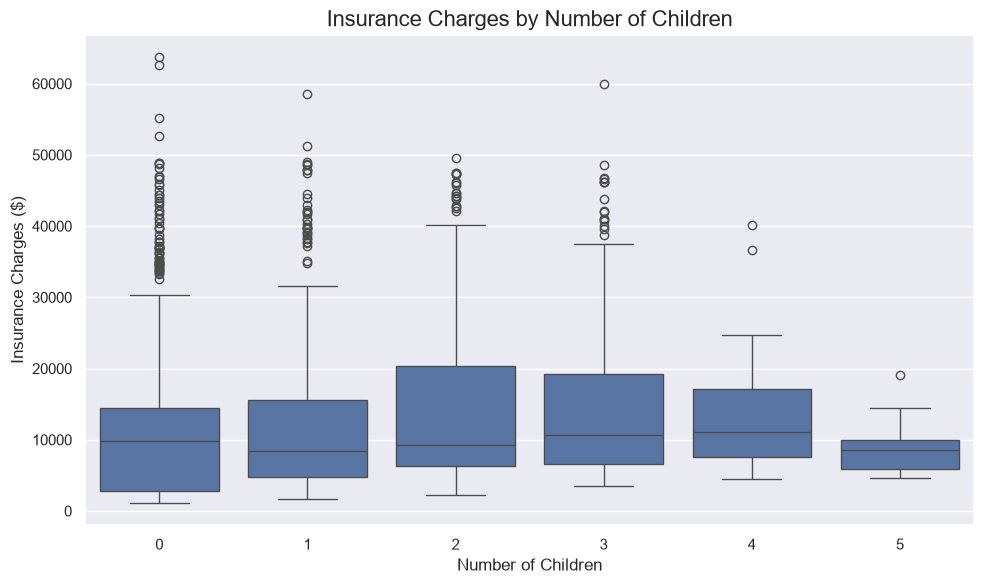

In [87]:
# Create a figure that is 10 inches wide and 6 inches tall.
plt.figure(figsize=(10, 6))

# Draw one box per number of children.
sns.boxplot(data=df, x="no_of_children", y="insurance_charges")

# Add a title and labels for both axes.
plt.title("Insurance Charges by Number of Children", fontsize=16)
plt.xlabel("Number of Children")
plt.ylabel("Insurance Charges ($)")

# Adjust spacing so the plot fits neatly, then display the chart.
plt.tight_layout()
plt.show()

**Observations**

- **There is no consistent trend.** Medians stay in a narrow range of about $8.5k to $11k across all groups and do not rise steadily with the number of children.
- **Boxes for 2 and 3 children are taller** (the middle 50% of charges spans roughly $6k to $20k), so charges are more spread out in those groups. The 0 and 1 groups have a similar median but a lower upper quartile.
- **The 0-children group has the most extreme outliers**, with charges running up to about $64k. It is also by far the largest group (573 records), so it is expected to contain more extreme cases.
- **The 4 and 5-children groups are small** (25 and 18 records). The 5-children box is very narrow, with all charges below about $19k, but this reflects the small sample and should not be read as a real effect.

**Interpretation**

The earlier table showed mean charges rising slightly up to 2–3 children and falling afterwards. The boxplot shows that this is not a reliable pattern: the medians barely move, the boxes overlap heavily, and the spread within each group is much larger than the differences between groups. `no_of_children` appears to be a weak predictor. Age and smoker status have not been accounted for here, so these differences should not be read as an effect of having children.

**Implication for modelling:** keep `no_of_children` in the baseline model, since it is cheap to include, but expect little predictive value. Consider treating it as numeric or capping it at "3+" because the 4 and 5 groups are too small to estimate reliably, and test whether removing it changes performance.

## **4. Summary and Conclusion**

### **Summary**

This notebook explored how six features (`age`, `sex`, `bmi`, `no_of_children`, `smoker`, `region`) relate to individual insurance charges across 1,337 records. Scatter plots examined age and BMI against charges, boxplots and summary tables compared charges across the categorical features, and crosstabs checked whether differences in smoker share explain the apparent sex and region effects.

### **Key Findings**

1. **Smoking status is the dominant driver of charges.** Smokers are about 20% of records (274 of 1,337) but account for roughly half of all charges. Their mean charge is **$32,050 vs $8,441** for non-smokers (about 3.8 times higher), and **every charge above about $37k belongs to a smoker**.
2. **Age has a steady positive effect.** Charges rise with age within every band, and the non-smoker band follows a tight, almost linear trend. Smoking also changes how fast charges grow with age.
3. **BMI matters mainly for smokers, and mainly above BMI 30.** Smokers show a step up in charges near BMI 30, while non-smokers stay roughly flat across the BMI range. This is an interaction effect.
4. **The apparent sex effect is mostly smoker share.** Males have a higher mean charge ($13,975 vs $12,570), but the medians are almost identical ($9,378 vs $9,413). A higher share of smokers among males (23.6% vs 17.4%) accounts for nearly all of the mean gap in a rough back-of-envelope check.
5. **The apparent region effect is also largely smoker share.** The southeast has the highest mean charge ($14.7k) and the highest smoker share (25.0%, vs 17.8% to 20.7% elsewhere), and the ranking of regions by mean charge matches their ranking by smoker share. The spread within each region ($11k to $14k) is much larger than the gaps between regions.
6. **The number of children has no consistent relationship with charges.** Medians stay between about $8.5k and $11k, boxes overlap heavily, and the groups with 4 and 5 children are too small (25 and 18 records) to draw conclusions.
7. **Charges are right-skewed.** The mean exceeds the median in every group examined, and every boxplot has a long upper tail of expensive records.

### **Implications for Modelling**

| Finding | Planned action |
|---|---|
| Smoker is dominant | Core feature in every model |
| Smoker × BMI interaction | Add `smoker × bmi` and an `obese` flag (BMI ≥ 30) for linear models; tree-based models should find it automatically |
| Smoker changes the age trend | Test an `age × smoker` interaction |
| Sex and region effects are largely smoker share | Keep in the baseline model, then test whether removing them changes performance |
| Weak children effect | Treat as numeric or cap at "3+", then test whether it adds anything |
| Skewed charges | Compare models on raw and log-transformed charges, and report errors in dollars |
| Smokers are a small group with about half of all charges | Use a train/test split stratified on `smoker` |
| Categorical text columns | One-hot encode inside a pipeline to avoid data leakage |

### **Limitations**

- Relationships were judged mainly from plots and summary tables, not tested statistically. The smoker-share explanation for the sex and region gaps is a rough check, not a formal test.
- The children comparison does not control for age or smoker status.
- A group of non-smokers with mid-range charges (roughly $15k to $37k) is not explained by the available features and was not investigated in this notebook.
- The data is observational and small (about 1,300 records), so these are associations, not causal effects, and model comparisons should use cross-validation.

### **Conclusion**

Insurance charges in this dataset are driven mainly by **smoking status**. **Age** adds a steady increase, and **BMI** raises charges further for smokers above BMI 30. **Sex** and **region** show only small differences that appear to be largely explained by how many smokers each group contains, and **number of children** shows no consistent effect. A model that captures the smoker × BMI interaction and handles the skewed charges is expected to outperform a plain linear model on the raw features, so interaction handling and the treatment of skewed charges are the main design questions for the modelling notebook.

**Next:** notebook 03 builds baseline and interaction-based regression models, compares them with cross-validation, and tests whether the weak features (`sex`, `region`, `no_of_children`) add any predictive value once `smoker` is included.